#Exercícios Análise Assintótica - Parte II

Vamos utilizar agora a biblioteca  timeit, onde poderemos executar métodos ou funções dentro de um ambiente que permite realizar medição de tempo de forma similar. Trata-se de uma forma mais precisa para avaliar o tempo de execução dos métodos. Clique [aqui](https://docs.python.org/3/library/timeit.html) e [aqui](https://www.geeksforgeeks.org/timeit-python-examples/) para maiores informações sobre o uso de timeit.


# Exemplo 01

In [9]:

import timeit

# Código a ser medido
def my_function():
  """Função de exemplo para medir o tempo de execução."""
  result = 0
  for i in range(1000000):
    result += i
  return result

# Medir o tempo de execução da função
execution_time = timeit.timeit(my_function, number=10)

print(f"Tempo de execução da função: {execution_time:.6f} segundos")

Tempo de execução da função: 0.745593 segundos


#Exemplo 02

Execute o código abaixo para entender o uso de Timer para criar objetos. Isso facilita a manipulaçao da funçao para avaliar o tempo de execução.

In [10]:
import timeit

def my_function():
  """Função exemplo para medir o tempo de execução."""
  result = 0
  for i in range(1000000):
    result += i
  return result

# Criando um objeto Timer para medir o tempo de execução da função
tempo = timeit.Timer(stmt='my_function()', globals=globals())

# Parâmetros do Timer:
# stmt: A string que representa o código a ser executado.
#       Neste caso, 'my_function()' chama a função my_function.
# globals: Um dicionário que contém as variáveis globais que serão usadas durante a execução do código.
#       Neste caso, globals() passa todas as variáveis globais, incluindo a função my_function.


# Medindo o tempo de execução da função 10 vezes e retornando o tempo médio
execution_time = tempo.timeit(number=10)

print(f"Tempo de execução da função: {execution_time:.6f} segundos")

Tempo de execução da função: 0.794312 segundos


#Exercício 01

Substitua a função do exercício anterior por outra que calcule iterativamente o valor da série abaixo para uma entrada n.

    s=1+2+3+4...+n

Execute 5 vezes variando o valor inicial de n=10 fazendo n*=10

Exiba o tempo de execução.

#Solução

In [11]:
import timeit

def my_func_01(n):
    s = 0
    for i in range(1 , n + 1):
        s += i
    return s

n = 1983

for i in range(5):
    tempo = timeit.Timer(stmt="my_func_01(n)", globals=globals())
    execution_time = tempo.timeit(number=5)
    print(f"Função executada em {execution_time:.6f}s")
    print(f"Nesse passo n vale:{n}.")
    print(f"resultado de myfunc_01:{my_func_01(n)}.")
    print(40 * "-")
    n *= 10

Função executada em 0.001792s
Nesse passo n vale:1983.
resultado de myfunc_01:1967136.
----------------------------------------
Função executada em 0.022176s
Nesse passo n vale:19830.
resultado de myfunc_01:196624365.
----------------------------------------
Função executada em 0.128877s
Nesse passo n vale:198300.
resultado de myfunc_01:19661544150.
----------------------------------------
Função executada em 1.391065s
Nesse passo n vale:1983000.
resultado de myfunc_01:1966145491500.
----------------------------------------
Função executada em 12.007554s
Nesse passo n vale:19830000.
resultado de myfunc_01:196614459915000.
----------------------------------------


#Exercício 02

Comparar o desempenho da função executada iterativamente com uma função que retorna o valor usando a fórumula:

    s=n*(n+1)//2

Plotar os resultados do tempo de execução de cada função para valores distintos de n usando pontos em um mesmo gráfico.  

Varie o valor de n fazendo:

    for n in range(10,1000,10)

#Solução

In [12]:
import timeit

def my_func_01(n):
    s = 0
    for i in range(1 , n + 1):
        s += i
    return s

def my_func_02(n):
    s = 0
    s = n*(n+1)//2
    return s

x = []
execucao_iter = []
execucao_form = []


for n in range(10, 1000, 10):
    
    x.append(n)
    
    tempo = timeit.Timer(stmt=f"my_func_01({n})", globals=globals())
    execution_time_iter = tempo.timeit(number=5)
    
    execucao_iter.append(execution_time_iter)
    
    tempo = timeit.Timer(stmt=f"my_func_02({n})", globals=globals())
    execution_time_form = tempo.timeit(number=5)

    execucao_form.append(execution_time_form)


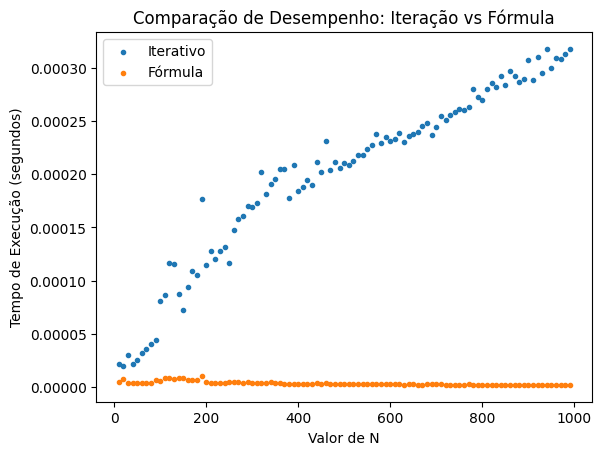

In [13]:
import matplotlib.pyplot as plt

plt.scatter(x,execucao_iter, marker=".")
plt.scatter(x,execucao_form, marker=".")

plt.title("Comparação de Desempenho: Iteração vs Fórmula")
plt.xlabel("Valor de N")
plt.ylabel("Tempo de Execução (segundos)")
plt.legend(["Iterativo", "Fórmula"])


plt.show()


#Exercício 03
Modificar o código abaixo para executar a função PG iterativa implementada no exercício 09 da Parte I.




In [14]:

import timeit
import math

def func(n):
  return math.sqrt(n)

'''
Valor de entrada deve ser declarado antes de executar
'''
n=100

'''
Transforma em string os imports necessários para executar
sqrt e a funçao func criada no código
'''
mysetup = '''
from math import sqrt
from __main__ import func
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
mycode = f'''
func({n})
'''

t = timeit.Timer(setup=mysetup, stmt=mycode)

# executar 1000 vezes e retornar o tempo médio em segundos
print(t.timeit(number=1000))


0.00043729999993047386


#Solução

Codigo modificado para executar a função iterativa da PG

In [15]:
import timeit

def func(a1, r, n):
    pg=[]
    for _ in range(n):
        pg.append(a1)
        a1 *= r
    return a1

'''
Valor de entrada deve ser declarado antes de executar
'''
a1 = 1
r = 2
n = 100

'''
Transforma em string os imports necessários para executar
sqrt e a funçao func criada no código
'''
mysetup = '''
from __main__ import func
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
mycode = f'''
func({a1},{r},{n})
'''

t = timeit.Timer(setup=mysetup, stmt=mycode)

# executar 1000 vezes e retornar o tempo médio em segundos
print(t.timeit(number=1000))

0.02872439999987364


#Exercício 04

Plote gráficos comparando o desempenho das funções PG iterativa e PG recursiva usando timeit. Para isso, avalie os resultados variando o valor de n como sugerido abaixo:

for n in range(10,1000,10)

Utilize 1000 repetições para o cálculo do tempo médio usando timeit.

    timeit(number=1000)

Você deve plotar no eixo x os valores de i e no eixo y o tempo gasto para calcular o valor da série.



#Solução

In [16]:
import timeit

def func(a1, r, n):
    pg=[]
    for _ in range(n):
        pg.append(a1)
        a1 *= r
    return a1
import timeit

'''
Valor de entrada deve ser declarado antes de executar
'''
a1 = 1
r = 2

'''
Transforma em string os imports necessários para executar                     
sqrt e a funçao func criada no código
'''
mysetup = '''
from __main__ import func
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
execucoes_iter = []
tempo_iter=[]

for n in range(10, 1000, 10):
    mycode = f'''func({a1},{r},{n})'''
    t_mat = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = t_mat.timeit(number=1000)
    tempo_iter.append(t_medio)
    execucoes_iter.append(n)

In [17]:
import timeit

def func(a1, r, n):
    pg=a1*(r**n)
    return pg

'''
Valor de entrada deve ser declarado antes de executar
'''
a1 = 1
r = 2

'''
Transforma em string os imports necessários para executar
sqrt e a funçao func criada no código
'''
mysetup = '''
from __main__ import func
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
execucoes_mat = []
tempo_mat=[]

for n in range(10, 1000, 10):
    mycode = f'''func({a1},{r},{n})'''
    t_mat = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = t_mat.timeit(number=1000)
    tempo_mat.append(t_medio)
    execucoes_mat.append(n)

In [18]:
a= len(execucoes_mat)
b= len(tempo_mat)
display(a,b)

99

99

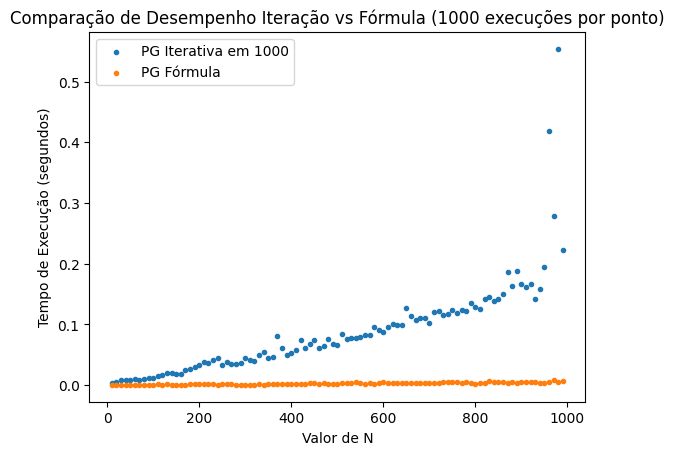

In [19]:
import matplotlib.pyplot as plt

eixo_x = list(range(0, 10000, 10))

fig, ax = plt.subplots()

ax.scatter(execucoes_iter, tempo_iter, marker=".",label="PG Iterativa em 1000")
ax.scatter(execucoes_mat, tempo_mat, marker=".",label="PG Fórmula")

plt.title("Comparação de Desempenho Iteração vs Fórmula (1000 execuções por ponto)")
plt.xlabel("Valor de N")
plt.ylabel("Tempo de Execução (segundos)")
ax.legend()

plt.show()

<font color='orange'>O gráfico ilustra a eficiência da abordagem matemática. O cálculo através da fórmula mantém um tempo de execução constante, com complexidade O(1). Por outro lado, o método iterativo mostra o crescimento linear O(n) com o aumento de N. Isto mostra que fórmulas matemáticas são computacionalmente mais eficientes do que a utilização de laços de repetição. 

#Exercício 05

Compare o desempenho de concatenar + e append(). Para isso, crie duas funções, uma usando + e outra usando append que inclua elementos numa lista vazia conforme sugerido abaixo:

lista=[ ]

for n in range(10,1000,10):

\<incluir n em lista\>

Plotar um gráfico comparando o desempenho.


Utilize 1000 repetições para o cálculo do tempo médio usando timeit.

    timeit(number=1000)



#Solução

In [125]:
def popular_lista_c():
    lista=[]
    for n in range(10,1000,10):
        lista = lista + [i]
    return lista

def popular_lista_a():
    lista=[]
    for n in range(10,1000,10):
        lista.append(n)
    return lista

In [132]:
mysetup = '''
from __main__ import popular_lista_c
'''
mycode = f'''
popular_lista_c({n})
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
tempo_concat=[]

for n in range(10, 1000, 10):
    mycode = f'''popular_lista_c()'''
    t_mat = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = t_mat.timeit(number=1000)
    tempo_concat = tempo_concat + [t_medio]
    
len(tempo_concat)

99

In [127]:
mysetup = '''
from __main__ import popular_lista_a
'''
mycode = f'''
popular_lista_a({n})
'''
'''
Transforma em string a função a ser executada
Observe que usar o formatador f'' permite incluir o valor
da variável n dentro da string
'''
tempo_append=[]

for n in range(10, 1000, 10):
    mycode = f'''popular_lista_a()'''
    t_mat = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = t_mat.timeit(number=1000)
    tempo_append.append(t_medio)

len(tempo_append)

99

In [120]:
eixo_x = list(range(10, 1000, 10))
len(eixo_x)

99

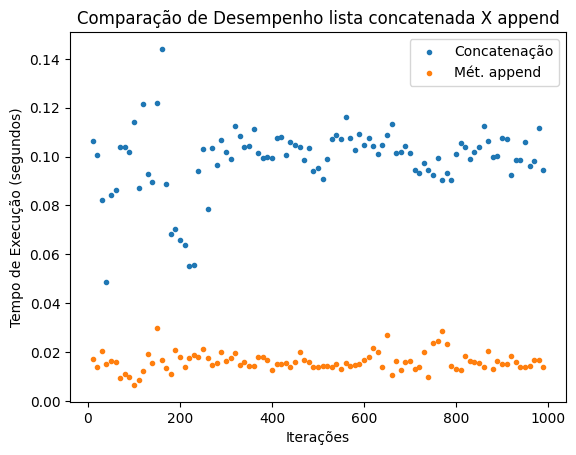

In [133]:
fig, ax = plt.subplots()

ax.scatter(eixo_x, tempo_concat, marker=".", label="Concatenação")
ax.scatter(eixo_x, tempo_append, marker=".", label="Mét. append")

plt.title("Comparação de Desempenho lista concatenada X append")
plt.xlabel("Iterações")
plt.ylabel("Tempo de Execução (segundos)")
ax.legend()

plt.show()

<font color='orange'>O gráfico ilustra a diferença computacional do método de concatenação que recria a lista a cada iteração, configurando um caso On de crescimento linear visto que a cada vez qua a lista aumenta o computador precisa recriar uma estrutura ainda maior. O método ´append´ é melhor computacionalmente pois ele trabalha alocando um espaço extra na lista evitando todo o reprocessamento configurando um caso de computação constante (O1).

#Exercício 06

Repita a mesma análise da atividade anterior comparando agora desempenho de pop(0) e pop(). Para isso, crie uma lista de listas como abaixo e utilize para comparar os métodos.

    listas = []

    for n in range(11000,101000,100):

      x= list(range(n))

      listas.append(x)

Utilize 1000 repetições para o cálculo do tempo médio usando timeit.

    timeit(number=1000)


Plotar um gráfico comparando o desempenho.



#Solução

In [86]:
def pop():
    for i in range(len(listas)):
        listas[i].pop()
        
def pop_zero():
    for i in range(len(listas)):
        listas[i].pop(0)

In [87]:
tempo_pop = []

for i in range(10,100,10):
    listas = []
    for n in range(11000,101000,100):
      x= list(range(n))
      listas.append(x)    
    
    mysetup='''from __main__ import pop'''
    mycode = '''pop()'''
    
    obj_tempo = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = obj_tempo.timeit(number=1000)
    tempo_pop.append(t_medio)

In [88]:
tempo_pop_z = []

for i in range(10,100,10):
    listas = []
    for n in range(11000,101000,100):
      x= list(range(n))
      listas.append(x)    
    
    mysetup='''from __main__ import pop_zero'''
    mycode = '''pop_zero()'''
    
    obj_tempo = timeit.Timer(setup=mysetup, stmt=mycode)
    t_medio = obj_tempo.timeit(number=1000)
    tempo_pop_z.append(t_medio)

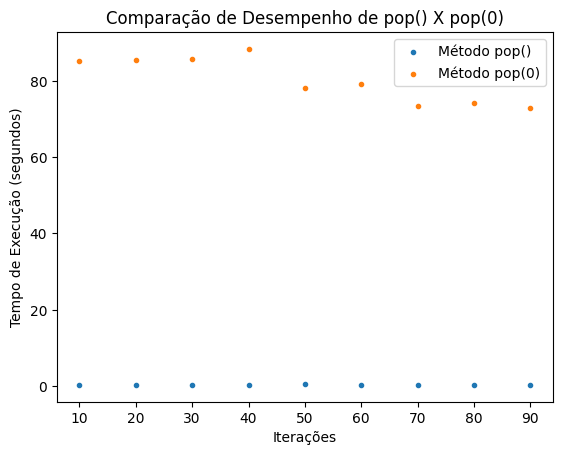

In [90]:
fig, ax = plt.subplots()

eixo_x = list(range(10,100,10))
len(eixo_x)

ax.scatter(eixo_x, tempo_pop, marker=".", label="Método pop()")
ax.scatter(eixo_x, tempo_pop_z, marker=".", label="Método pop(0)")

plt.title("Comparação de Desempenho de pop() X pop(0)")
plt.xlabel("Iterações")
plt.ylabel("Tempo de Execução (segundos)")
ax.legend()

plt.show()

<font color='orange'>O método pop() tem o tempo de execução muito mais rápido devido ao pouco manuseio de memória. Como não é necessário realocar nenhuma posição da lista a não ser a última o tempo de execução é contínuo (O1). O método pop(0) comporta-se da maneira inversa, pois quando o primeiro endereço da lista é retirado abre-se um buraco na primeira posição fazendo-se necessário realocar cada endereço uma posição à esquerda caracterizando o crescimento linear (On) da exigência computacional.

#Exercício 07

Repita a mesma análise da atividade anterior comparando o desempenho de **in** para dicionários e lista. Para isso, crie uma lista de listas e uma listas de dicionário como sugerido abaixo.

    listas = []
    for n in range(100,100000,1000):
      l=[i for i in range(n)]
      listas.append(l)

    listas=[]
    for n in range(100,100000,1000):
      dic = {i:None for i in range(n)}
      listas.append(dic)

Para avaliar **in** usando uma lista l ou um dicionário d, utilize a função random como abaixo:

    random.randrange(n) in l
    random.randrange(n) in d

Utilize 1000 repetições para o cálculo do tempo médio usando timeit.

    timeit(number=1000)


Plotar um gráfico comparando o desempenho.



#Solução

In [102]:
listas_l = []
eixo_n = list(range(100, 100000, 1000))

for n in eixo_n:
    l = [i for i in range(n)]
    listas_l.append(l)

listas_d = []
for n in eixo_n:
    dic = {i: None for i in range(n)}
    listas_d.append(dic)

tempo_lista = []
tempo_dic = []

In [103]:
for indice, n in enumerate(eixo_n):

    mysetup_lista = f'''
from __main__ import listas_l
import random
l = listas_l[{indice}]
n = {n}
'''
    mycode_lista = '''random.randrange(n) in l'''
    
    t_lista = timeit.Timer(setup=mysetup_lista, stmt=mycode_lista)
    t_medio_l = t_lista.timeit(number=1000)
    tempo_lista.append(t_medio_l)

    mysetup_dic = f'''
from __main__ import listas_d
import random
d = listas_d[{indice}]
n = {n}
'''
    mycode_dic = '''random.randrange(n) in d'''
    
    t_dic = timeit.Timer(setup=mysetup_dic, stmt=mycode_dic)
    t_medio_d = t_dic.timeit(number=1000)
    tempo_dic.append(t_medio_d)



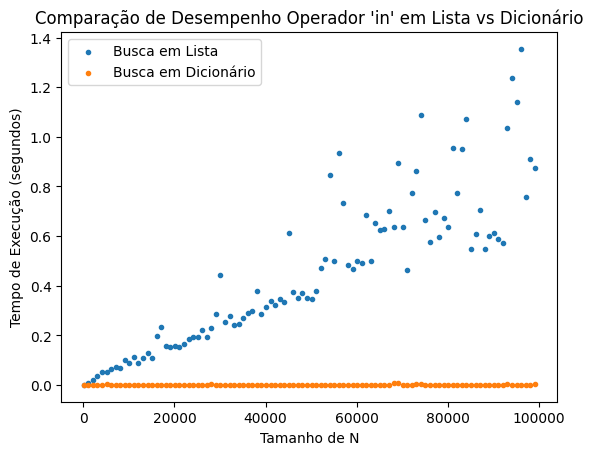

In [104]:
fig, ax = plt.subplots()

ax.scatter(eixo_n, tempo_lista, marker=".", label="Busca em Lista")
ax.scatter(eixo_n, tempo_dic, marker=".", label="Busca em Dicionário")

plt.title("Comparação de Desempenho Operador 'in' em Lista vs Dicionário")
plt.xlabel("Tamanho de N")
plt.ylabel("Tempo de Execução (segundos)")
ax.legend()

plt.show()

<font color='orange'>A busca em lista mostra a tendência de crescimento linear On, onde o tempo de execução aumenta a medida que o tamanho da lista aumenta. Por outro lado, a busca em dicionário é mais eficiente, isso acontece devido a sua caracteristica estrutural onde é possivel utilizar operações matemáticas para percorrer os dados mantendo o tempo de execução constante.